# Image → Tensor

In [1]:
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt

image_path = "images/image.jpg"

image_bgr = cv2.imread(image_path)

if image_bgr is None:
    raise FileNotFoundError(f"Could not load image: {image_path}")

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

print("Image shape:", image_rgb.shape)
print("Image dtype:", image_rgb.dtype)

Image shape: (2400, 1320, 3)
Image dtype: uint8


In [2]:
image_tensor = torch.from_numpy(image_rgb)
print("shape: ", image_tensor.shape)
print("dype: ",image_tensor.dtype)

shape:  torch.Size([2400, 1320, 3])
dype:  torch.uint8


In [3]:
image_tensor = image_tensor.permute(2, 0, 1).float()

print("Shape:", image_tensor.shape)
print("Dtype:", image_tensor.dtype)
print("Min:", image_tensor.min().item())
print("Max:", image_tensor.max().item())

Shape: torch.Size([3, 2400, 1320])
Dtype: torch.float32
Min: 0.0
Max: 255.0


In [4]:
print("Original NumPy shape:", image_rgb.shape)
print("Tensor shape:", image_tensor.shape)

Original NumPy shape: (2400, 1320, 3)
Tensor shape: torch.Size([3, 2400, 1320])


# Tensor → Image

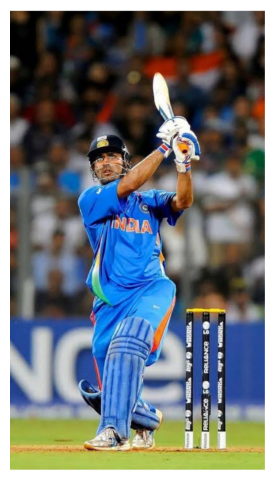

In [6]:
image_for_display = image_tensor.permute(1, 2, 0).numpy()

plt.figure(figsize=(8, 6))
plt.imshow(image_for_display.astype(np.uint8))
plt.axis("off")
plt.show()

# Normalization

In [7]:
# Scale pixels to [0, 1]

image_normalized = image_tensor / 255.0

print("Dtype:", image_normalized.dtype)
print("Min:", image_normalized.min().item())
print("Max:", image_normalized.max().item())

Dtype: torch.float32
Min: 0.0
Max: 1.0


In [8]:
# Normalize using mean and standard deviation
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

image_standardized = (image_normalized - mean) / std

print("Shape:", image_standardized.shape)
print("Mean:", image_standardized.mean().item())
print("Std:", image_standardized.std().item())

Shape: torch.Size([3, 2400, 1320])
Mean: -0.2777848541736603
Std: 1.1996350288391113


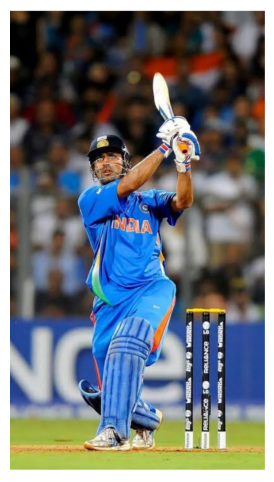

In [11]:
image_recovered = image_standardized * std + mean

image_recovered = (
    image_recovered
    .clamp(0, 1)
    .permute(1, 2, 0)
    .numpy()
)

plt.figure(figsize=(8, 6))
plt.imshow(image_recovered)
plt.axis("off")
plt.show()

# Batch Creation

In [12]:
batch = torch.stack([
    image_normalized,
    image_normalized,
    image_normalized
])

print("Batch shape:", batch.shape)
print("Batch dtype:", batch.dtype)

Batch shape: torch.Size([3, 3, 2400, 1320])
Batch dtype: torch.float32


In [13]:
print("First image shape:", batch[0].shape)
print("Second image shape:", batch[1].shape)

First image shape: torch.Size([3, 2400, 1320])
Second image shape: torch.Size([3, 2400, 1320])


In [14]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

batch = batch.to(device)

print("Device:", batch.device)
print("Batch shape:", batch.shape)

Device: cuda:0
Batch shape: torch.Size([3, 3, 2400, 1320])


# Complete Pipeline

In [15]:
import cv2
import numpy as np
import torch

# 1. Load image
image_bgr = cv2.imread("images/image.jpg")

if image_bgr is None:
    raise FileNotFoundError("Image could not be loaded.")

# 2. Convert BGR → RGB
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

# 3. NumPy → PyTorch tensor
image_tensor = torch.from_numpy(image_rgb.copy())

# 4. HWC → CHW and uint8 → float32
image_tensor = image_tensor.permute(2, 0, 1).float()

# 5. Normalize to [0, 1]
image_tensor = image_tensor / 255.0

# 6. Create a batch containing one image
batch = image_tensor.unsqueeze(0)

# 7. Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
batch = batch.to(device)

print("Batch shape:", batch.shape)
print("Dtype:", batch.dtype)
print("Device:", batch.device)
print("Min:", batch.min().item())
print("Max:", batch.max().item())

Batch shape: torch.Size([1, 3, 2400, 1320])
Dtype: torch.float32
Device: cuda:0
Min: 0.0
Max: 1.0
